In [2]:
%pip install torch torchvision torchaudio

   ---------------------------------------- 0.0/126.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/126.7 MB ? eta -:--:--
   ---------------------------------------- 1.0/126.7 MB 6.9 MB/s eta 0:00:19
   ---------------------------------------- 1.6/126.7 MB 4.3 MB/s eta 0:00:30
    --------------------------------------- 2.9/126.7 MB 5.0 MB/s eta 0:00:25
   - -------------------------------------- 5.5/126.7 MB 7.0 MB/s eta 0:00:18
   -- ------------------------------------- 7.6/126.7 MB 7.9 MB/s eta 0:00:16
   -- ------------------------------------- 8.7/126.7 MB 7.3 MB/s eta 0:00:17
   --- ------------------------------------ 12.1/126.7 MB 8.6 MB/s eta 0:00:14
   ---- ----------------------------------- 13.6/126.7 MB 8.6 MB/s eta 0:00:14
   ---- ----------------------------------- 15.5/126.7 MB 8.6 MB/s eta 0:00:13
   ----- ---------------------------------- 16.8/126.7 MB 8.9 MB/s eta 0:00:13
   ----- ---------------------------------- 17.6/126.7 MB 8.4 MB/s eta 0:0

In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("All libraries imported successfully!")

PyTorch: 2.15.0+cpu
Torchvision: 0.29.2+cpu
All libraries imported successfully!


In [4]:
import torch

x = torch.tensor([1, 2, 3])
print("Tensor:", x)
print("Device:", x.device)
print("PyTorch working:", torch.cuda.is_available())

Tensor: tensor([1, 2, 3])
Device: cpu
PyTorch working: False


In [5]:
import torch
import torch.nn as nn
import torch.optim as optim

import torchvision
import torchvision.datasets as datasets
import torchvision.transforms as transforms

import matplotlib.pyplot as plt
import numpy as np

from torch.utils.data import DataLoader, random_split

from sklearn.metrics import classification_report, confusion_matrix

import seaborn as sns

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("All libraries imported successfully!")

PyTorch: 2.15.0+cpu
Torchvision: 0.29.2+cpu
All libraries imported successfully!


In [6]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.datasets as datasets
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np

from torch.utils.data import DataLoader, random_split
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("All libraries imported successfully!")

PyTorch: 2.15.0+cpu
Torchvision: 0.29.2+cpu
All libraries imported successfully!


In [8]:
# Load CIFAR-10 dataset

transform = transforms.ToTensor()

train_dataset = datasets.CIFAR10(
    root='../Exercise 02 - CNN/data',
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.CIFAR10(
    root='../Exercise 02 - CNN/data',
    train=False,
    download=True,
    transform=transform
)

print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))

100%|██████████| 170M/170M [21:36<00:00, 132kB/s]    


Training samples: 50000
Testing samples: 10000


In [9]:
transform = transforms.ToTensor()

train_dataset = datasets.CIFAR10(
    root='../Exercise 02 - CNN/data',
    train=True,
    download=False,
    transform=transform
)

test_dataset = datasets.CIFAR10(
    root='../Exercise 02 - CNN/data',
    train=False,
    download=False,
    transform=transform
)

print("Training Images:", len(train_dataset))
print("Testing Images:", len(test_dataset))
print("CIFAR-10 Dataset Loaded Successfully!")

Training Images: 50000
Testing Images: 10000
CIFAR-10 Dataset Loaded Successfully!


In [10]:
# Split dataset into training and validation

generator = torch.Generator().manual_seed(42)

train_subset, val_subset = random_split(
    train_dataset,
    [45000, 5000],
    generator=generator
)

print("Training Images:", len(train_subset))
print("Validation Images:", len(val_subset))
print("Testing Images:", len(test_dataset))

print("Dataset splitting completed successfully!")

Training Images: 45000
Validation Images: 5000
Testing Images: 10000
Dataset splitting completed successfully!


In [11]:
# Batch size
BATCH_SIZE = 64

# Training DataLoader
train_loader = DataLoader(
    train_subset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

# Validation DataLoader
val_loader = DataLoader(
    val_subset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Testing DataLoader
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

print("DataLoaders created successfully!")

Training batches: 704
Validation batches: 79
Testing batches: 157
DataLoaders created successfully!


In [12]:
class DropoutCNN(nn.Module):

    def __init__(self):
        super(DropoutCNN, self).__init__()

        self.conv_layers = nn.Sequential(

            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )

        self.fc_layers = nn.Sequential(

            nn.Flatten(),

            nn.Linear(64 * 8 * 8, 256),
            nn.ReLU(),

            nn.Dropout(0.5),

            nn.Linear(256, 10)
        )

    def forward(self, x):
        x = self.conv_layers(x)
        x = self.fc_layers(x)
        return x


# Create Dropout CNN model
model = DropoutCNN()

print(model)
print("Dropout CNN model created successfully!")

DropoutCNN(
  (conv_layers): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc_layers): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=256, out_features=10, bias=True)
  )
)
Dropout CNN model created successfully!


In [13]:
# Define loss function
criterion = nn.CrossEntropyLoss()

# Define optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Dropout CNN Loss Function:", criterion)
print("Dropout CNN Optimizer:", optimizer)
print("Dropout model configuration completed!")

Dropout CNN Loss Function: CrossEntropyLoss()
Dropout CNN Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)
Dropout model configuration completed!


In [14]:
def train_model(model, train_loader, criterion, optimizer):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(train_loader)
    accuracy = 100 * correct / total

    return epoch_loss, accuracy


print("Dropout CNN Training function created successfully!")

Dropout CNN Training function created successfully!


In [15]:
def evaluate_model(model, data_loader, criterion):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in data_loader:

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(data_loader)
    accuracy = 100 * correct / total

    return epoch_loss, accuracy


print("Dropout CNN Validation function created successfully!")

Dropout CNN Validation function created successfully!


In [16]:
EPOCHS = 10

train_losses = []
train_accuracies = []

val_losses = []
val_accuracies = []

for epoch in range(EPOCHS):

    train_loss, train_acc = train_model(
        model, train_loader, criterion, optimizer
    )

    val_loss, val_acc = evaluate_model(
        model, val_loader, criterion
    )

    train_losses.append(train_loss)
    train_accuracies.append(train_acc)

    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    print(f"Epoch [{epoch+1}/{EPOCHS}]")
    print(f"Training Loss: {train_loss:.4f}")
    print(f"Training Accuracy: {train_acc:.2f}%")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_acc:.2f}%")
    print("-" * 40)

print("Dropout CNN Training Completed!")

Epoch [1/10]
Training Loss: 1.5858
Training Accuracy: 42.32%
Validation Loss: 1.3259
Validation Accuracy: 53.72%
----------------------------------------
Epoch [2/10]
Training Loss: 1.2346
Training Accuracy: 55.79%
Validation Loss: 1.0767
Validation Accuracy: 61.94%
----------------------------------------
Epoch [3/10]
Training Loss: 1.1086
Training Accuracy: 60.36%
Validation Loss: 1.0076
Validation Accuracy: 64.40%
----------------------------------------
Epoch [4/10]
Training Loss: 1.0222
Training Accuracy: 63.63%
Validation Loss: 0.9575
Validation Accuracy: 66.20%
----------------------------------------
Epoch [5/10]
Training Loss: 0.9593
Training Accuracy: 66.24%
Validation Loss: 0.9012
Validation Accuracy: 68.02%
----------------------------------------
Epoch [6/10]
Training Loss: 0.9021
Training Accuracy: 68.10%
Validation Loss: 0.9086
Validation Accuracy: 68.16%
----------------------------------------
Epoch [7/10]
Training Loss: 0.8595
Training Accuracy: 69.43%
Validation Loss

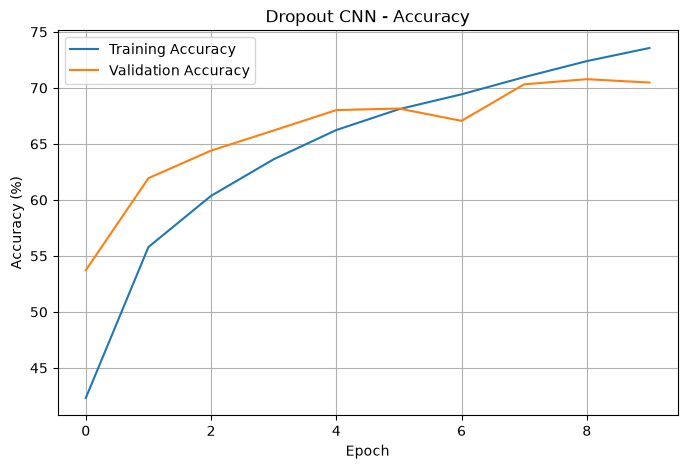

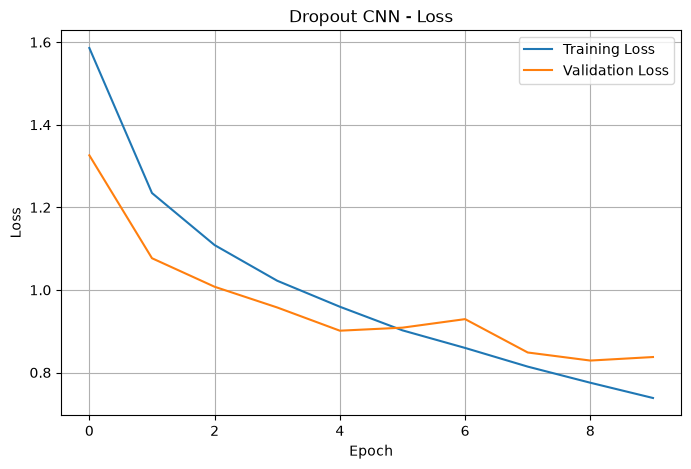

In [17]:
# Training and Validation Accuracy Graph

plt.figure(figsize=(8, 5))

plt.plot(train_accuracies, label='Training Accuracy')
plt.plot(val_accuracies, label='Validation Accuracy')

plt.title('Dropout CNN - Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True)
plt.show()


# Training and Validation Loss Graph

plt.figure(figsize=(8, 5))

plt.plot(train_losses, label='Training Loss')
plt.plot(val_losses, label='Validation Loss')

plt.title('Dropout CNN - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

In [18]:
test_loss, test_accuracy = evaluate_model(
    model,
    test_loader,
    criterion
)

print("Dropout CNN Final Test Results")
print("------------------------------")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2f}%")
print("Dropout CNN Evaluation Completed!")

Dropout CNN Final Test Results
------------------------------
Test Loss: 0.8379
Test Accuracy: 70.73%
Dropout CNN Evaluation Completed!


In [19]:
# Define data augmentation transformations

augmentation_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ToTensor()
])

# Load augmented training dataset
augmented_train_dataset = datasets.CIFAR10(
    root='../Exercise 02 - CNN/data',
    train=True,
    download=False,
    transform=augmentation_transform
)

print("Data Augmentation Transformations:")
print(augmentation_transform)

print("Augmented Training Dataset:", len(augmented_train_dataset))
print("Data Augmentation configured successfully!")

Data Augmentation Transformations:
Compose(
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-10.0, 10.0], interpolation=nearest, expand=False, fill=0)
    ToTensor()
)
Augmented Training Dataset: 50000
Data Augmentation configured successfully!


In [20]:
# Split augmented dataset

aug_train_subset, aug_val_subset = random_split(
    augmented_train_dataset,
    [45000, 5000],
    generator=torch.Generator().manual_seed(42)
)

# Create DataLoaders

aug_train_loader = DataLoader(
    aug_train_subset,
    batch_size=64,
    shuffle=True
)

aug_val_loader = DataLoader(
    aug_val_subset,
    batch_size=64,
    shuffle=False
)

print("Augmented Training Images:", len(aug_train_subset))
print("Validation Images:", len(aug_val_subset))
print("Training Batches:", len(aug_train_loader))
print("Validation Batches:", len(aug_val_loader))

print("Augmented DataLoaders created successfully!")

Augmented Training Images: 45000
Validation Images: 5000
Training Batches: 704
Validation Batches: 79
Augmented DataLoaders created successfully!


In [21]:
class AugmentationCNN(nn.Module):
    def __init__(self):
        super(AugmentationCNN, self).__init__()

        self.conv_layers = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )

        self.fc_layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 256),
            nn.ReLU(),
            nn.Linear(256, 10)
        )

    def forward(self, x):
        x = self.conv_layers(x)
        x = self.fc_layers(x)
        return x


aug_model = AugmentationCNN()

criterion = nn.CrossEntropyLoss()

aug_optimizer = optim.Adam(
    aug_model.parameters(),
    lr=0.001
)

print("Augmentation CNN model created successfully!")
print(aug_model)

Augmentation CNN model created successfully!
AugmentationCNN(
  (conv_layers): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc_layers): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=10, bias=True)
  )
)


In [22]:
EPOCHS = 10

aug_train_losses = []
aug_train_accuracies = []

aug_val_losses = []
aug_val_accuracies = []

for epoch in range(EPOCHS):

    train_loss, train_acc = train_model(
        aug_model,
        aug_train_loader,
        criterion,
        aug_optimizer
    )

    val_loss, val_acc = evaluate_model(
        aug_model,
        val_loader,
        criterion
    )

    aug_train_losses.append(train_loss)
    aug_train_accuracies.append(train_acc)

    aug_val_losses.append(val_loss)
    aug_val_accuracies.append(val_acc)

    print(f"Epoch [{epoch+1}/{EPOCHS}]")
    print(f"Training Loss: {train_loss:.4f}")
    print(f"Training Accuracy: {train_acc:.2f}%")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_acc:.2f}%")
    print("-" * 40)

print("Data Augmentation Training Completed!")

Epoch [1/10]
Training Loss: 1.4934
Training Accuracy: 46.24%
Validation Loss: 1.2594
Validation Accuracy: 54.76%
----------------------------------------
Epoch [2/10]
Training Loss: 1.1552
Training Accuracy: 58.92%
Validation Loss: 1.0771
Validation Accuracy: 61.32%
----------------------------------------
Epoch [3/10]
Training Loss: 1.0215
Training Accuracy: 63.82%
Validation Loss: 0.9796
Validation Accuracy: 64.86%
----------------------------------------
Epoch [4/10]
Training Loss: 0.9294
Training Accuracy: 67.26%
Validation Loss: 0.9191
Validation Accuracy: 67.64%
----------------------------------------
Epoch [5/10]
Training Loss: 0.8659
Training Accuracy: 69.40%
Validation Loss: 0.8610
Validation Accuracy: 69.86%
----------------------------------------
Epoch [6/10]
Training Loss: 0.8095
Training Accuracy: 71.66%
Validation Loss: 0.8552
Validation Accuracy: 70.16%
----------------------------------------
Epoch [7/10]
Training Loss: 0.7643
Training Accuracy: 73.15%
Validation Loss

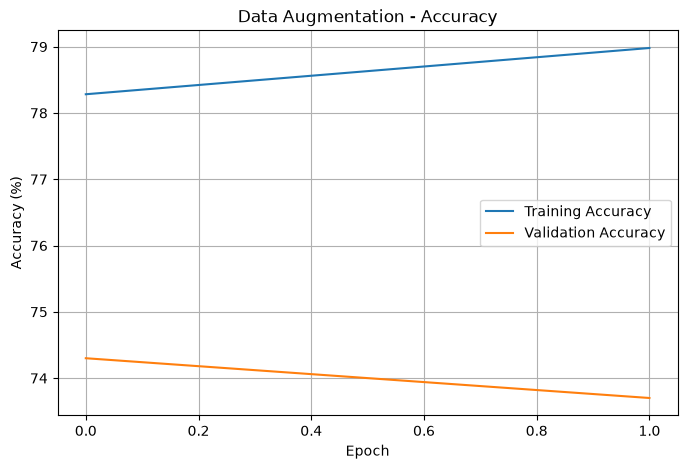

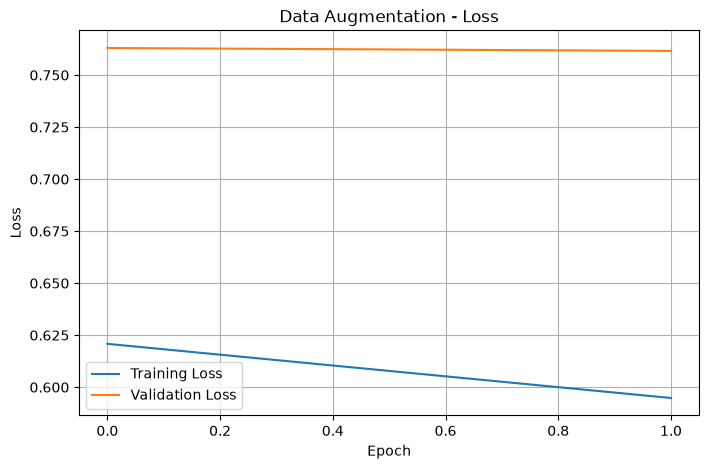

In [24]:
# Augmentation Training and Validation Accuracy

plt.figure(figsize=(8, 5))

plt.plot(aug_train_accuracies, label='Training Accuracy')
plt.plot(aug_val_accuracies, label='Validation Accuracy')

plt.title('Data Augmentation - Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True)
plt.show()


# Augmentation Training and Validation Loss

plt.figure(figsize=(8, 5))

plt.plot(aug_train_losses, label='Training Loss')
plt.plot(aug_val_losses, label='Validation Loss')

plt.title('Data Augmentation - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

In [25]:
aug_test_loss, aug_test_accuracy = evaluate_model(
    aug_model,
    test_loader,
    criterion
)

print("Data Augmentation CNN Final Test Results")
print("----------------------------------------")
print(f"Test Loss: {aug_test_loss:.4f}")
print(f"Test Accuracy: {aug_test_accuracy:.2f}%")
print("Data Augmentation Evaluation Completed!")

Data Augmentation CNN Final Test Results
----------------------------------------
Test Loss: 0.7694
Test Accuracy: 74.53%
Data Augmentation Evaluation Completed!


In [26]:
import pandas as pd

comparison_data = {
    "Model": [
        "Baseline CNN",
        "Dropout CNN",
        "Data Augmentation CNN"
    ],
    "Test Accuracy (%)": [
        70.58,
        test_accuracy,
        aug_test_accuracy
    ]
}

comparison_df = pd.DataFrame(comparison_data)

print("MODEL PERFORMANCE COMPARISON")
print("============================")
display(comparison_df)

MODEL PERFORMANCE COMPARISON


,Model,Test Accuracy (%)
0,Baseline CNN,70.58
1,Dropout CNN,70.73
2,Data Augmentation CNN,74.53


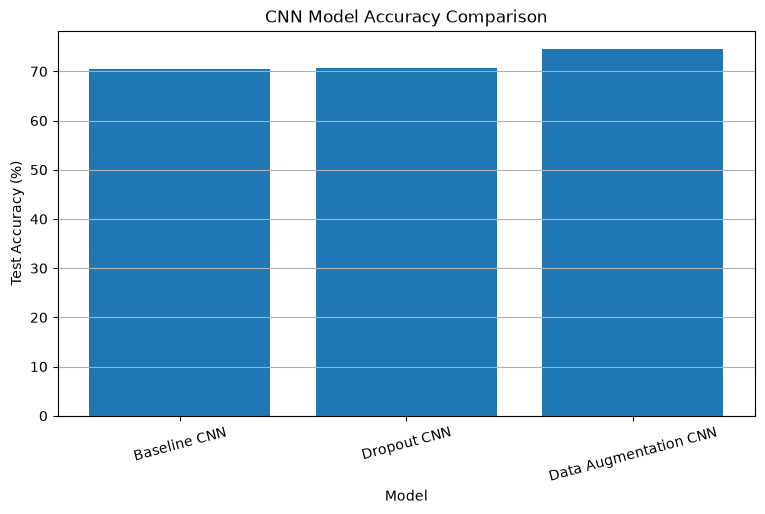

In [27]:
plt.figure(figsize=(9, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["Test Accuracy (%)"]
)

plt.title("CNN Model Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Test Accuracy (%)")
plt.xticks(rotation=15)
plt.grid(axis='y')
plt.show()

In [28]:
print("==========================================")
print("EXERCISE 03 - FINAL RESULTS SUMMARY")
print("==========================================")

print("Dataset: CIFAR-10")
print("Training Images: 45000")
print("Validation Images: 5000")
print("Testing Images: 10000")
print("Epochs: 10")
print("------------------------------------------")

print("Baseline CNN Accuracy: 70.58%")
print(f"Dropout CNN Accuracy: {test_accuracy:.2f}%")
print(f"Data Augmentation CNN Accuracy: {aug_test_accuracy:.2f}%")

print("------------------------------------------")
print("Experiment 01: Dropout")
print("Experiment 02: Data Augmentation")
print("------------------------------------------")

print("Exercise 03 completed!")

EXERCISE 03 - FINAL RESULTS SUMMARY
Dataset: CIFAR-10
Training Images: 45000
Validation Images: 5000
Testing Images: 10000
Epochs: 10
------------------------------------------
Baseline CNN Accuracy: 70.58%
Dropout CNN Accuracy: 70.73%
Data Augmentation CNN Accuracy: 74.53%
------------------------------------------
Experiment 01: Dropout
Experiment 02: Data Augmentation
------------------------------------------
Exercise 03 completed!
